In [ ]:
# Add relevant Jupyter notebook extensions

Repository: C:\Users\rkdes\OneDrive\Documents\Oxford Year 3\B1 Computing\b1-coding-practical-mt26-team


In [ ]:
# You can double-check your Python path like this...
import sys  
print(sys.path) 

Mission samples: 100
Simulation and reset checks passed
['C:\\Users\\rkdes\\OneDrive\\Documents\\Oxford Year 3\\B1 Computing\\b1-coding-practical-mt26-team', 'C:\\Users\\rkdes\\OneDrive\\Documents\\Oxford Year 3\\B1 Computing\\b1-coding-practical-mt26-team', 'C:\\Users\\rkdes\\OneDrive\\Documents\\Oxford Year 3\\B1 Computing\\b1-coding-practical-mt26-team', 'C:\\Users\\rkdes\\OneDrive\\Documents\\Oxford Year 3\\B1 Computing\\b1-coding-practical-mt26-team', 'C:\\Users\\rkdes\\OneDrive\\Documents\\Oxford Year 3\\B1 Computing\\b1-coding-practical-mt26-team', 'C:\\Users\\rkdes\\OneDrive\\Documents\\Oxford Year 3\\B1 Computing\\b1-coding-practical-mt26-team', 'C:\\Users\\rkdes\\OneDrive\\Documents\\Oxford Year 3\\B1 Computing\\b1-coding-practical-mt26-team', 'C:\\Users\\rkdes\\AppData\\Local\\Programs\\Python\\Python312\\python312.zip', 'C:\\Users\\rkdes\\AppData\\Local\\Programs\\Python\\Python312\\DLLs', 'C:\\Users\\rkdes\\AppData\\Local\\Programs\\Python\\Python312\\Lib', 'C:\\Users\\rkd

# Simulate closed-loop
After implementing your control functionality, you can simulate the closed-loop with code that looks something like this...

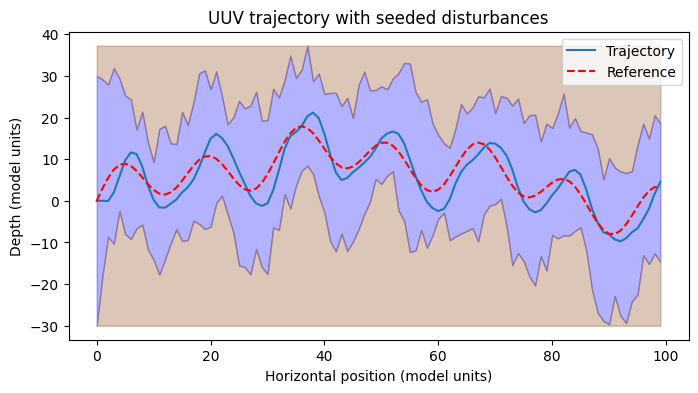

In [ ]:
# Import relevant modules
from pathlib import Path
import sys
import matplotlib.pyplot as plt

# Identify the repository root and adds it to the Python path so the specific mission modules can be imported
ROOT = Path.cwd().resolve()
if not (ROOT / "uuv_mission").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "uuv_mission").is_dir(), "Open the clone folder in VS Code"
sys.path.insert(0, str(ROOT))

# Imports mission-relevant modules and libraries
from uuv_mission.dynamic import Mission, Submarine, ClosedLoop
from uuv_mission.control import PDController

# Create instance of the submarine
sub = Submarine()

# Instantiate your controller (depending on your implementation)
closed_loop = ClosedLoop(sub, PDController())
mission = Mission.from_csv(ROOT / "data" / "mission.csv") # You must implement this method in the Mission class
trajectory = closed_loop.simulate_with_random_disturbances(mission)

# Plot the submarine trajectory with disturbances
fig = plt.figure(figsize=(8, 4))
plt.xlabel("Horizontal position (model units)")
plt.ylabel("Depth (model units)")
plt.title("UUV trajectory with random disturbances")
trajectory.plot_completed_mission(mission) # Plots the trajectory along with the reference route
fig.savefig(ROOT / "trajectory.png", dpi=200, bbox_inches="tight")